In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
# 1. Import Database

In [3]:
conn = sqlite3.connect('customer_churn_1.db')

sql_query = """
        SELECT name 
        FROM sqlite_master
        Where type = 'table';
        
"""

tables = pd.read_sql(sql_query, conn)                                                                    # to read sql query in pd we use read_query

#create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [4]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0000-BDRNE,kavita,India,Delhi,Female,1992-10-11 00:00:00,NaN,None
1,0000-EPVGA,kabita,India,Delhi,Female,1996-10-21 00:00:00,NaN,None
2,0000-HVETX,divya,India,Maharashtra,Female,1976-07-24 00:00:00,NaN,None
3,0000-JCHJV,preeti,India,Maharashtra,Female,1989-03-27 00:00:00,NaN,None
4,0000-MRCYJ,mayank,India,Meghalaya,Male,1982-11-17 00:00:00,NaN,None


In [5]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_names in tables['name']:
    print(f"\nTable Name: {table_names}")
    #Get column information
    columns_query = f"PRAGMA table_info({table_names});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

#Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [6]:
# 2. Data Cleaning

In [7]:
#df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
99995,9999-TMLJM,tarun,India,Telangana,Male,1985-06-05 00:00:00,NaN,None
99996,9999-UOSCK,puja,India,Karnataka,Women,1985-05-01 00:00:00,NaN,None
99997,9999-XBOHR,rishabh,India,Maharashtra,Male,1992-05-08 00:00:00,NaN,None
99998,9999-YRVHI,durga,India,Delhi,Female,1983-06-25 00:00:00,NaN,None
99999,9999-ZOIBY,shreya,India,Telangana,Women,1988-05-17 00:00:00,NaN,None


In [8]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   customerid  100000 non-null  str   
 1   name        100000 non-null  str   
 2   country     85792 non-null   str   
 3   state       100000 non-null  str   
 4   gender      100000 non-null  str   
 5   dob         100000 non-null  str   
 6   interests   19099 non-null   str   
 7   pincode     0 non-null       object
dtypes: object(1), str(7)
memory usage: 6.1+ MB


In [9]:
# a. rename col - name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values - country

In [10]:
# a. rename col - name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True) 
df_db_customer.head()
#inplace is used to fix a value in its place, like customer_name in place of name

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0000-BDRNE,kavita,India,Delhi,Female,1992-10-11 00:00:00,NaN,None
1,0000-EPVGA,kabita,India,Delhi,Female,1996-10-21 00:00:00,NaN,None
2,0000-HVETX,divya,India,Maharashtra,Female,1976-07-24 00:00:00,NaN,None
3,0000-JCHJV,preeti,India,Maharashtra,Female,1989-03-27 00:00:00,NaN,None
4,0000-MRCYJ,mayank,India,Meghalaya,Male,1982-11-17 00:00:00,NaN,None


In [11]:
# b. drop columns - interest and pincode

#df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
#df_db_customer.drop(df_db_customer.columns[6:], axis=1)

df_db_customer.drop(columns=['interests', 'pincode'], inplace = True)

In [12]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   customerid     100000 non-null  str  
 1   customer_name  100000 non-null  str  
 2   country        85792 non-null   str  
 3   state          100000 non-null  str  
 4   gender         100000 non-null  str  
 5   dob            100000 non-null  str  
dtypes: str(6)
memory usage: 4.6 MB


In [13]:
# c. change data type - dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [14]:
# d. data standardization - gender

df_db_customer['gender'].unique()

<StringArray>
['Female', 'Male', 'Men', 'Women']
Length: 4, dtype: str

In [15]:
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [16]:
df_db_customer['gender'].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [17]:
# e. fix missing values - country

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
11,0001-GEPTL,jitendra,NaN,Kathmandu,Male,1982-11-24
13,0001-JLLRW,anjali,NaN,Delhi,Female,1989-12-14
25,0002-IOYZO,Vaishali,NaN,Delhi,Female,1985-07-27
31,0003-INMZJ,kamala,NaN,Rajasthan,Female,1984-04-14
32,0003-IXSTX,deepak,NaN,Rajasthan,Male,1989-11-23
...,...,...,...,...,...,...
99940,9994-HMHJB,bhavna,NaN,Delhi,Female,1993-06-09
99960,9996-DLJRH,anjali,NaN,Maharashtra,Female,1993-04-07
99972,9997-YBENL,prakash,NaN,Meghalaya,Male,1994-06-25
99974,9998-FBFCG,seema,NaN,Delhi,Female,1997-03-16


In [18]:
#country and state - unique value pair

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

#print(state_country_mapping)

In [19]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [20]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0000-BDRNE,2020-11-05,Paid,2025-11-05,Standard,Annual,NaN,NaN,17.99,810,8
1,0000-EPVGA,2020-12-21,Organic,2025-12-21,Premium,Annual,NaN,NaN,22.99,1960,16
2,0000-HVETX,2021-02-23,Refferal,2024-02-23,Standard,Monthly,2024-03-31,Not enough content,13.99,400,88
3,0000-JCHJV,2019-02-09,Organic,2025-02-09,Premium,Annual,NaN,NaN,22.99,1900,41
4,0000-MRCYJ,2023-07-06,Refferal,2024-07-06,Standard,Monthly,2024-08-24,Poor streaming quality,13.99,110,96


In [21]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   customerid               100000 non-null  str    
 1   subscription_start_date  100000 non-null  str    
 2   subscription_type        100000 non-null  str    
 3   renewal_date             100000 non-null  str    
 4   plan_type                100000 non-null  str    
 5   contract_type            100000 non-null  str    
 6   cancellation_date        28612 non-null   str    
 7   cancellation_reason      28612 non-null   str    
 8   monthly_charges          100000 non-null  float64
 9   cltv                     100000 non-null  int64  
 10  churn_score              100000 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 8.4 MB


In [22]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)

df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   customerid               100000 non-null  str           
 1   subscription_start_date  100000 non-null  datetime64[us]
 2   subscription_type        100000 non-null  str           
 3   renewal_date             100000 non-null  datetime64[us]
 4   plan_type                100000 non-null  str           
 5   contract_type            100000 non-null  str           
 6   cancellation_date        28612 non-null   datetime64[us]
 7   cancellation_reason      28612 non-null   str           
 8   monthly_charges          100000 non-null  float64       
 9   cltv                     100000 non-null  int64         
 10  churn_score              100000 non-null  int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 8.4 MB


In [23]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0000-HVETX,2024-03-14 00:00:00,N,30,None,NaN
1,0000-MRCYJ,2024-08-09 00:00:00,Y,25,None,NaN
2,0000-SZBYV,2024-06-13 00:00:00,Y,30,None,NaN
3,0000-SZBYV,2024-06-14 00:00:00,N,35,None,received refund
4,0000-UVBDF,2025-02-18 00:00:00,N,90,None,guidance to renew


In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 43362 entries, 0 to 43361
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      43362 non-null  str   
 1   complaint_date  43362 non-null  str   
 2   escalations     43362 non-null  str   
 3   csat_score      43362 non-null  int64 
 4   col_1           0 non-null      object
 5   comment         18385 non-null  str   
dtypes: int64(1), object(1), str(4)
memory usage: 2.0+ MB


In [25]:
df_db_support.drop(columns = ['col_1', 'comment'], inplace = True)

In [26]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 43362 entries, 0 to 43361
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customerid      43362 non-null  str  
 1   complaint_date  43362 non-null  str  
 2   escalations     43362 non-null  str  
 3   csat_score      43362 non-null  int64
dtypes: int64(1), str(3)
memory usage: 1.3 MB


In [27]:
df_db_support['complaint_date'] = df_db_support['complaint_date'].apply(pd.to_datetime)
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 43362 entries, 0 to 43361
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      43362 non-null  str           
 1   complaint_date  43362 non-null  datetime64[us]
 2   escalations     43362 non-null  str           
 3   csat_score      43362 non-null  int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 1.3 MB


In [28]:
# 3. Feature Engineering and Data Analysis

In [29]:
# create a new column using an existing column

df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [30]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0000-BDRNE,2020-11-05,Paid,2025-11-05,Standard,Annual,NaT,NaN,17.99,810,8,0
1,0000-EPVGA,2020-12-21,Organic,2025-12-21,Premium,Annual,NaT,NaN,22.99,1960,16,0
2,0000-HVETX,2021-02-23,Refferal,2024-02-23,Standard,Monthly,2024-03-31,Not enough content,13.99,400,88,1
3,0000-JCHJV,2019-02-09,Organic,2025-02-09,Premium,Annual,NaT,NaN,22.99,1900,41,0
4,0000-MRCYJ,2023-07-06,Refferal,2024-07-06,Standard,Monthly,2024-08-24,Poor streaming quality,13.99,110,96,1


In [31]:
# first fix support table duplicates then merge

In [32]:
#df_db_customer['customerid'].nunique()
#df_db_subscription['customerid'].nunique()
df_db_support['customerid'].nunique()

33329

In [33]:
#df_db_customer['customerid'].size
#df_db_subscription['customerid'].size
df_db_support['customerid'].size

43362

In [34]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [35]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep = 'last')

In [36]:
df_db_support['customerid'].size

33329

In [37]:
# merge df

df = (df_db_subscription
                .merge(df_db_customer, on = 'customerid', how = 'left')
                .merge(df_db_support, on = 'customerid', how = 'left'))

df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0000-BDRNE,2020-11-05,Paid,2025-11-05,Standard,Annual,NaT,NaN,17.99,810,...,0,kavita,India,Delhi,Female,1992-10-11,NaT,NaN,NaN,NaN
1,0000-EPVGA,2020-12-21,Organic,2025-12-21,Premium,Annual,NaT,NaN,22.99,1960,...,0,kabita,India,Delhi,Female,1996-10-21,NaT,NaN,NaN,NaN
2,0000-HVETX,2021-02-23,Refferal,2024-02-23,Standard,Monthly,2024-03-31,Not enough content,13.99,400,...,1,divya,India,Maharashtra,Female,1976-07-24,2024-03-14,N,30.0,1.0
3,0000-JCHJV,2019-02-09,Organic,2025-02-09,Premium,Annual,NaT,NaN,22.99,1900,...,0,preeti,India,Maharashtra,Female,1989-03-27,NaT,NaN,NaN,NaN
4,0000-MRCYJ,2023-07-06,Refferal,2024-07-06,Standard,Monthly,2024-08-24,Poor streaming quality,13.99,110,...,1,mayank,India,Meghalaya,Male,1982-11-17,2024-08-09,Y,25.0,1.0


In [38]:
df.shape

(100000, 21)

In [39]:
# To transfer all the data into an excel file we do: .to_csv
df.to_csv('exported_churn_analysis_project.csv', index = False)

In [40]:
# Data Analysis

In [41]:
# a. Churn Rate

In [42]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [43]:
churn_rate = df['churn_flag'].mean()*100
print("Churn rate = ", round(churn_rate,2), "%")

Churn rate =  28.61 %


In [44]:
# b. Retention Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")

Retention Rate =  71.39 %


In [45]:
# c. Churn by Plan type

churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name = 'churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           50.07
1   Premium            7.75
2  Standard           32.54


In [46]:
# d. i. Churn by state + sum(revenue) + count of users
# d. ii. Churn by subscription type + sum(revenue) + count of users

In [47]:
# d. i. Churn by state + sum(revenue) + count of users

churn_by_state = df.groupby('state')['churn_flag'].mean().mul(100).round(2).rename('churn_rate_pct')
print(churn_by_state)

state
Delhi            28.66
Karnataka        28.23
Kathmandu        28.78
Maharashtra      29.09
Meghalaya        28.76
Nagaland         28.18
Rajasthan        28.52
Telangana        27.96
Uttar Pradesh    28.75
Name: churn_rate_pct, dtype: float64


In [48]:
# Customer count of users by state

customer_by_state = (df.groupby('state')['customerid'].count().rename('customers')) 
print(customer_by_state)

state
Delhi            19484
Karnataka         9625
Kathmandu         9424
Maharashtra      14485
Meghalaya        14051
Nagaland          4716
Rajasthan         9266
Telangana         9550
Uttar Pradesh     9399
Name: customers, dtype: int64


In [49]:
# Revenue by state

# count of days users has our service : cancellation date else current date
#df['duration_days'] = (df['cancellation_date'].fillna(pd.Timestamp.today().normalize()) - df['subscription_start_date']).dt.days

today = pd.Timestamp.today()

df['tenure_days'] = np.where(                                                # where(condition, true then what, false then what)
                            df['cancellation_date'].notna(),
                            (df['cancellation_date'] - df['subscription_start_date']).dt.days,
                            (today - df['subscription_start_date']).dt.days
                            )
 
avg_tenure = df['tenure_days'].mean()
print("Avg tenure (Days) :", round(avg_tenure))

df['total_revenue'] = ((df['monthly_charges']/30)*df['tenure_days']).round(2)

Avg tenure (Days) : 1562


In [50]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,total_revenue
0,0000-BDRNE,2020-11-05,Paid,2025-11-05,Standard,Annual,NaT,NaN,17.99,810,...,India,Delhi,Female,1992-10-11,NaT,NaN,NaN,NaN,2163.0,1297.08
1,0000-EPVGA,2020-12-21,Organic,2025-12-21,Premium,Annual,NaT,NaN,22.99,1960,...,India,Delhi,Female,1996-10-21,NaT,NaN,NaN,NaN,2117.0,1622.33


In [51]:
revenue_by_state = df.groupby('state')['total_revenue'].sum().round(2)

In [52]:
by_state = pd.concat([churn_by_state, revenue_by_state, customer_by_state], axis = 1). reset_index()

print(by_state)

           state  churn_rate_pct  total_revenue  customers
0          Delhi           28.66    16691383.76      19484
1      Karnataka           28.23     8269017.73       9625
2      Kathmandu           28.78     8019311.78       9424
3    Maharashtra           29.09    12328323.03      14485
4      Meghalaya           28.76    12101738.16      14051
5       Nagaland           28.18     3997176.96       4716
6      Rajasthan           28.52     7986950.79       9266
7      Telangana           27.96     8272861.63       9550
8  Uttar Pradesh           28.75     8091863.85       9399


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   customerid               100000 non-null  str           
 1   subscription_start_date  100000 non-null  datetime64[us]
 2   subscription_type        100000 non-null  str           
 3   renewal_date             100000 non-null  datetime64[us]
 4   plan_type                100000 non-null  str           
 5   contract_type            100000 non-null  str           
 6   cancellation_date        28612 non-null   datetime64[us]
 7   cancellation_reason      28612 non-null   str           
 8   monthly_charges          100000 non-null  float64       
 9   cltv                     100000 non-null  int64         
 10  churn_score              100000 non-null  int64         
 11  churn_flag               100000 non-null  int64         
 12  customer_name            100

In [54]:
# d. ii. Churn by subscription type

df['subscription_type'].value_counts()
churn_rate_pct = df.groupby('subscription_type')['churn_flag'].mean().mul(100).round(2).rename('churn_rate_pct')
print(churn_rate_pct)

subscription_type
Organic     12.12
Paid        13.18
Refferal    69.02
Name: churn_rate_pct, dtype: float64


In [55]:
# sum(revenue) by subscription type

revenue_by_subscription_type = df.groupby('subscription_type')['total_revenue'].sum().round(2)
print(revenue_by_subscription_type)

subscription_type
Organic     41965893.57
Paid        30835462.38
Refferal    12957271.74
Name: total_revenue, dtype: float64


In [56]:
# count of users by subscription type

total_customers = df.groupby('subscription_type')['customerid'].count().rename('total_customers')

In [70]:
# Also, find revenue by subscription type per customer

revenue_per_customer = ( revenue_by_subscription_type / total_customers ).round(2).rename('revenue_per_customer')

print(revenue_per_customer)


subscription_type
Organic      978.18
Paid        1076.43
Refferal     455.41
Name: revenue_per_customer, dtype: float64


In [71]:
by_subscription_type = pd.concat([churn_rate_pct, revenue_by_subscription_type, total_customers, revenue_per_customer], axis=1). reset_index()

print(by_subscription_type.to_string())

  subscription_type  churn_rate_pct  total_revenue  total_customers  revenue_per_customer
0           Organic           12.12    41965893.57            42902                978.18
1              Paid           13.18    30835462.38            28646               1076.43
2          Refferal           69.02    12957271.74            28452                455.41


In [72]:
# e. ARPY - Avg Revenue per User

arpu = df['monthly_charges'].mean()
print("ARPU =", round(arpu, 2))

ARPU = 15.56


In [73]:
# f. Revenue at risk - revenue lost from churned users

revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at risk (Rs 'K') =", revenue_at_risk)

Revenue at risk (Rs 'K') = 374704.88


In [74]:
# g. Escalation Rate

escalation_rate = (df['escalations'] == 'Y').mean()*100
print("Escalation Rate =", round(escalation_rate, 2), "%")

Escalation Rate = 17.97 %


In [75]:
# h. Avg complaint per user

avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg complaints per user =", round(avg_complaints, 2))

Avg complaints per user = 0.43


In [76]:
# i. Correlation Escalation vs Churn

df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)    #encoding str to int type
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between escalation vs churn is =", round(correlation,2))

Correlation between escalation vs churn is = 0.74


In [77]:
# j. Create a column using exsisting columns - Churn risk
# acc to industry standards, if a user has a churn score higher than 70 then they are most likely to churn

conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default = 'unknown')

In [80]:
# 4. Visualisation using Matplotlib and Seaborn

In [81]:
df_visual = df.copy()

In [82]:
df_visual.shape

(100000, 24)

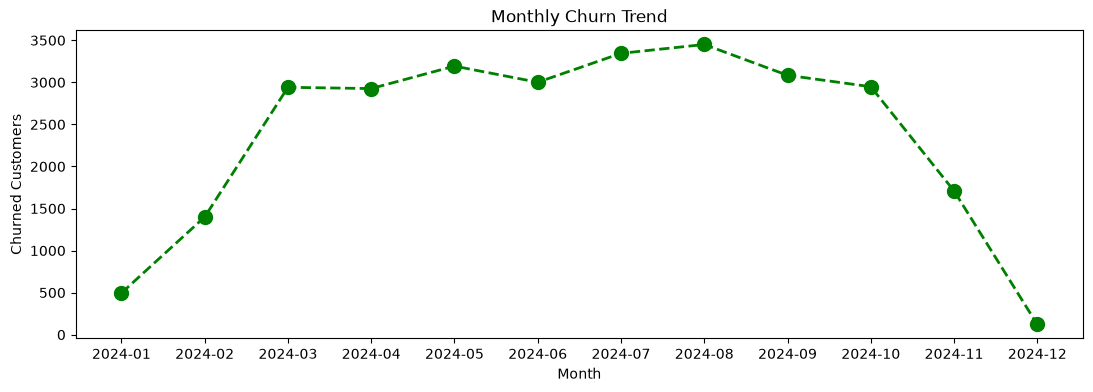

In [111]:
# 4. a. Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] ==1].groupby('cancellation_month').size()

plt.figure(figsize=(13,4))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=10)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

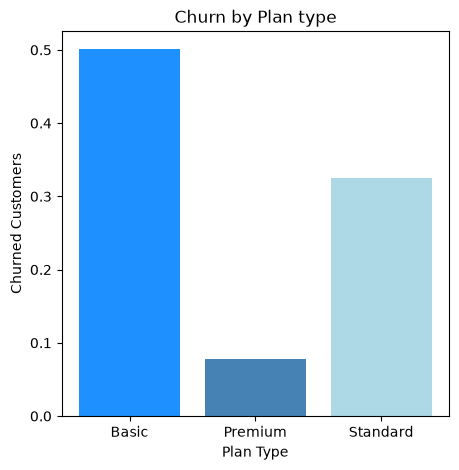

In [108]:
# 4. b. Churn by Plan type

churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

colors = ['dodgerblue', 'steelblue', 'lightblue']
#colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize = (5,5))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn by Plan type')
plt.xlabel('Plan Type')
plt.ylabel('Churned Customers')
plt.show()

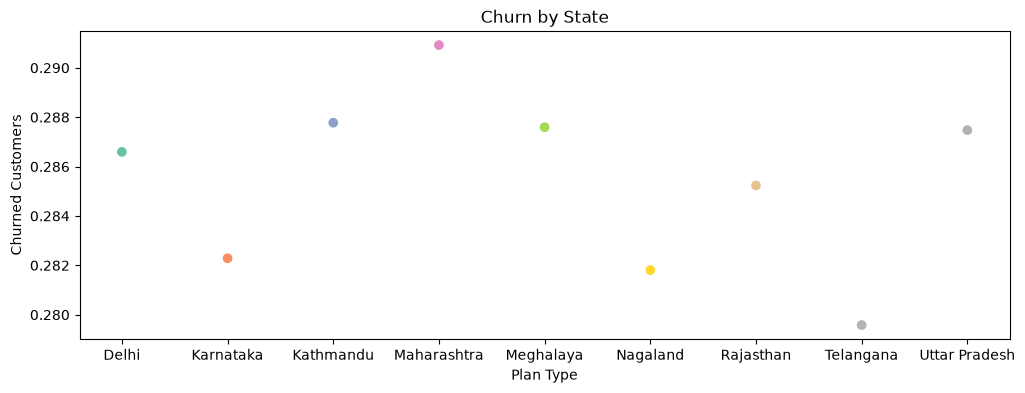

In [114]:
# 4. c. Churn by State

churn_plan = df_visual.groupby('state')['churn_flag'].mean()

#colors = ['lavender', 'pink', 'orange']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize = (12,4))
plt.scatter(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn by State')
plt.xlabel('Plan Type')
plt.ylabel('Churned Customers')
plt.show()

In [115]:
# Visualisation using Seaborn

In [116]:
# encoding - convert str to numeric so that we can find correlation between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'total_revenue', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [136]:
df_encoded = df[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

In [137]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,8,0,low,0
1,Premium,Annual,16,0,low,0
2,Standard,Monthly,88,1,high,0
3,Premium,Annual,41,0,low,0
4,Standard,Monthly,96,1,high,1


In [138]:
# Encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' :["Basic", 'Standard', 'Premium'], 
    'contract_type' :['Monthly', 'Annual'], 
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories = order, ordered = True).codes

In [139]:
df[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,8,0,low,0
1,Premium,Annual,16,0,low,0
2,Standard,Monthly,88,1,high,0
3,Premium,Annual,41,0,low,0
4,Standard,Monthly,96,1,high,1


In [140]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,8,0,0,0
1,2,1,16,0,0,0
2,1,0,88,1,2,0
3,2,1,41,0,0,0
4,1,0,96,1,2,1


<Axes: >

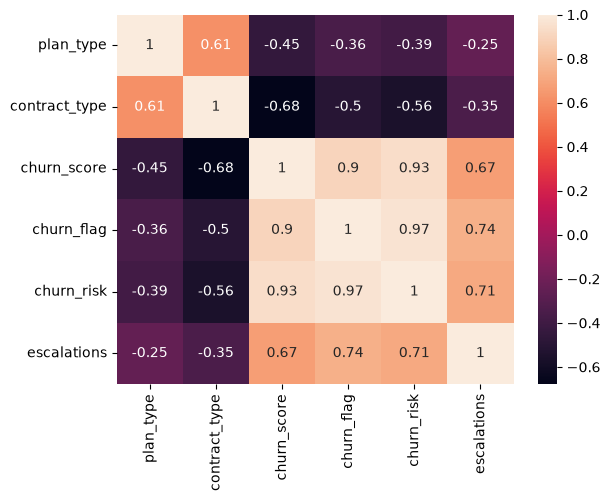

In [141]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot = True)

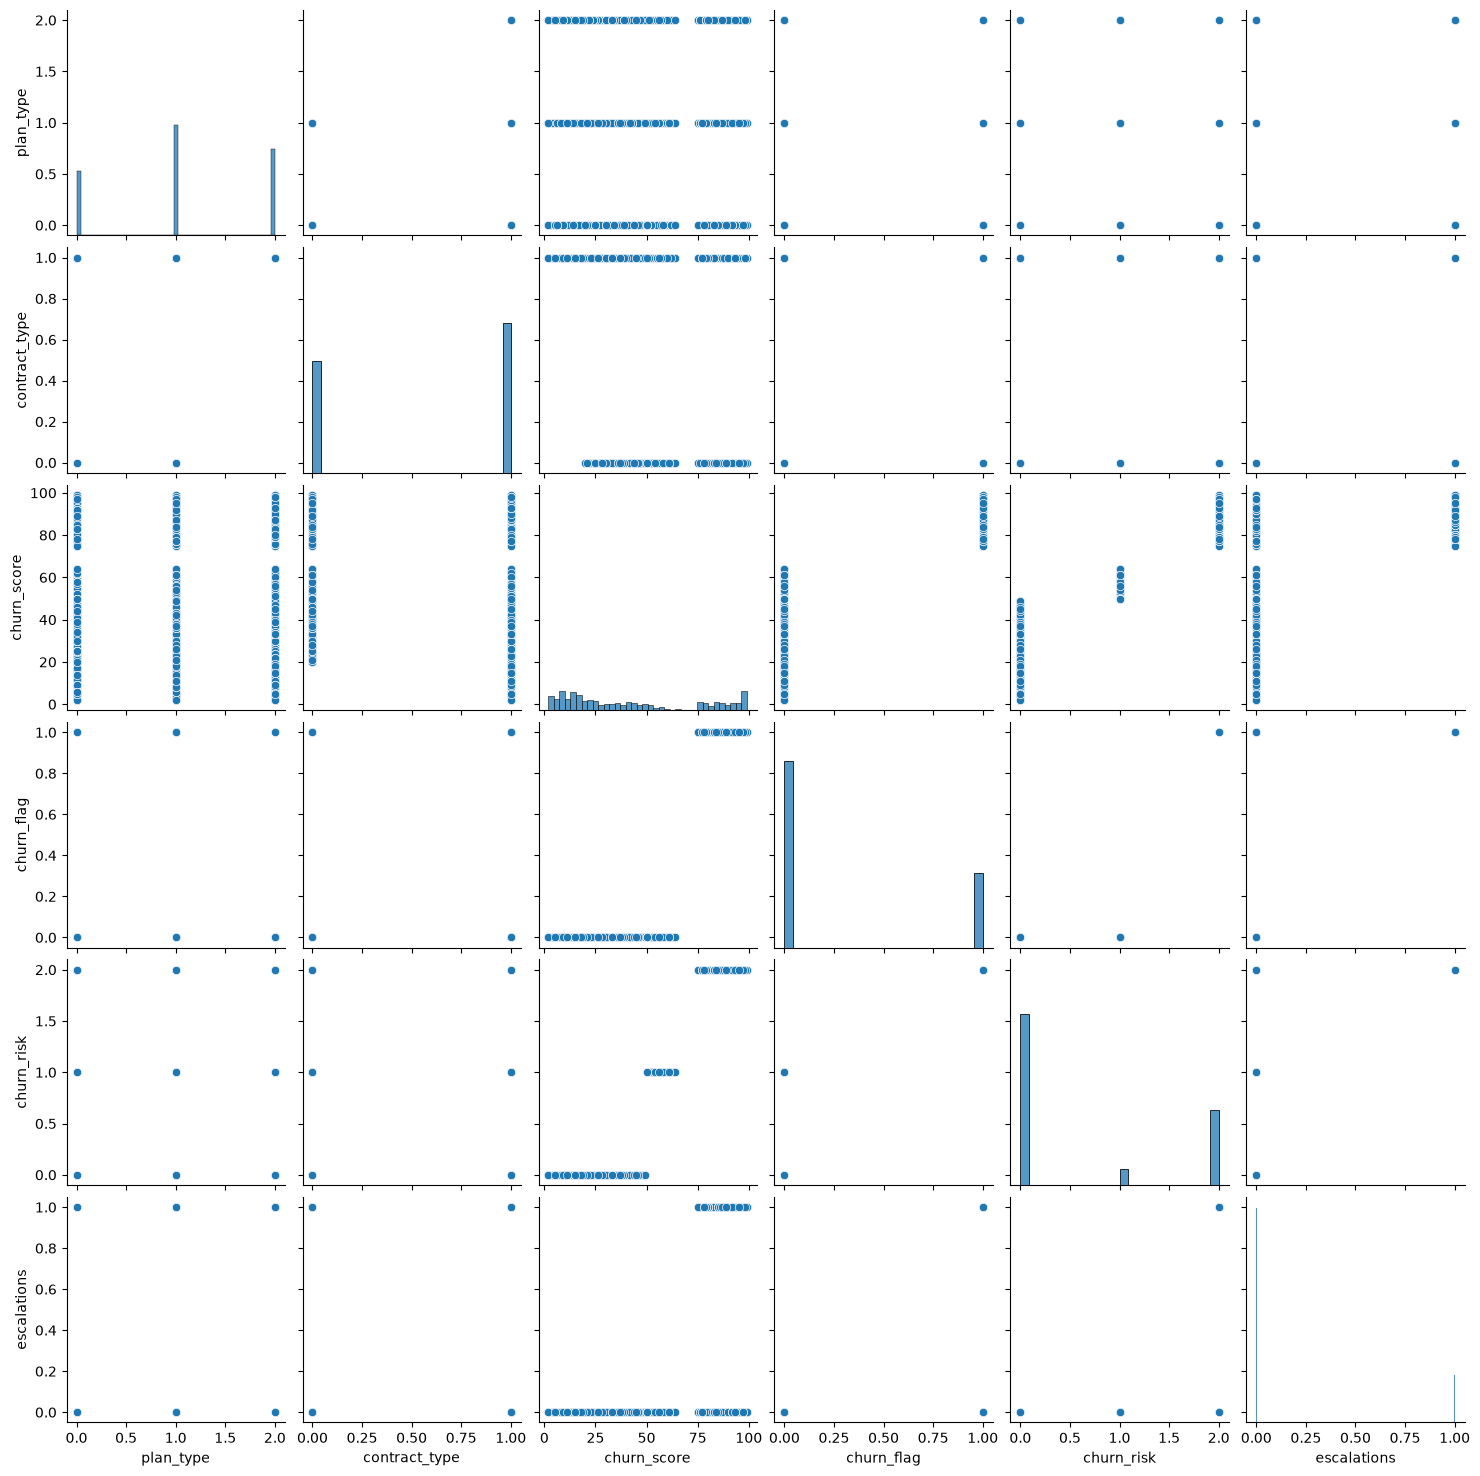

In [144]:
# pairplot - relationship in a dataset

sns. pairplot(df_encoded)

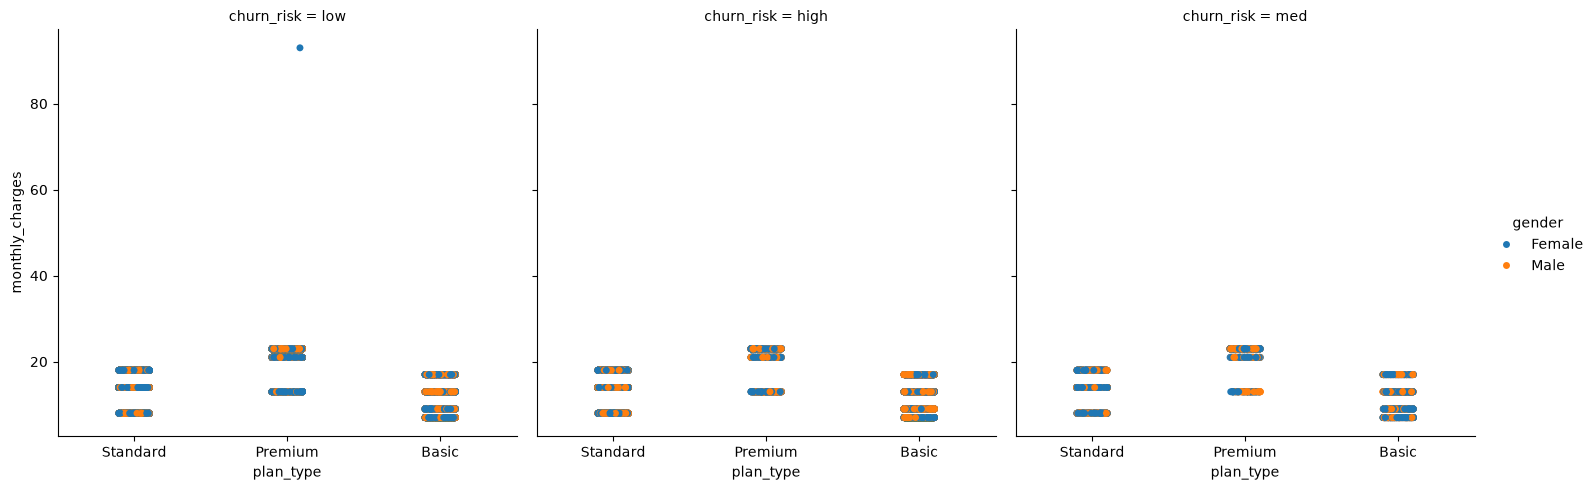

In [145]:
# catplt/Facegrid plot - Multi-dimension comparison

sns.catplot(data = df_visual,
            x = 'plan_type',
            y = 'monthly_charges',
            hue = 'gender',
            col = 'churn_risk')